# Pre-check de elegibilidad hipotecaria: el modelo de riesgo

**La idea en una frase.** Un cliente pregunta al chatbot por una hipoteca. Estimamos la probabilidad de que sea un **buen riesgo de crédito** a partir de datos que el banco ya tiene, la comparamos con un umbral y respondemos con un mensaje **orientativo**.

**El flujo (la parte que construye este notebook):**

```
 Recuperar perfil del cliente ──> Pedir solo lo que falta ──> Estimar P(buen riesgo)
                                                                    │
                                   P ≥ umbral ──> Mensaje "Potencialmente elegible" ──> continuar al cálculo
                                   P < umbral ──> Mensaje "No elegible con esta información (orientativo)"
```

El notebook sigue este orden: los datos, el modelo, qué tan bueno es, la matriz de confusión y la curva ROC, el umbral, el modelo final y un formulario interactivo.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, confusion_matrix, roc_curve

## 1. Los datos

In [2]:
df = pd.read_excel("Risk.xlsx")          # clientes pasados, con una etiqueta: risk = 1 (bueno) o 0 (malo)

print("Clientes:", len(df))
print(f"Buen riesgo: {df['risk'].mean():.0%}   Mal riesgo: {1 - df['risk'].mean():.0%}")
print("\nColumnas:", list(df.columns))

Clientes: 980
Buen riesgo: 43%   Mal riesgo: 57%

Columnas: ['id', 'age', 'gender', 'income', 'marital', 'numkids', 'numcards', 'mortgage', 'howpaid', 'storecar', 'loans', 'risk']


**Qué usamos y qué dejamos fuera.**

- **Usamos:** `age` (edad), `income` (ingresos), `numcards` (número de tarjetas), `storecar` (número de tarjetas de tienda: crédito caro), `loans` (número de préstamos), `numkids` (número de hijos), `mortgage` (si ya tiene hipoteca), `howpaid` (cómo cobra el cliente: semanal / mensual) y `marital` (estado civil).
- **Dejamos fuera:** `gender` (género) e `id`. El uso de género en decisiones de crédito está prohibido por las normas europeas de igualdad de trato.

In [3]:
NUMERICAS   = ["age", "income", "numcards", "storecar", "loans", "numkids"]
CATEGORICAS = ["mortgage", "howpaid", "marital"]
FUERA       = ["id", "gender"]
VARIABLES   = NUMERICAS + CATEGORICAS

## 2. El modelo: regresión logística

Una regresión logística toma los datos del cliente, da a cada uno un peso aprendido de clientes pasados, los suma y convierte el total en una probabilidad entre 0 % y 100 %. Antes hay tres pasos de preparación sencillos: **rellenar huecos** (la mediana en los números, el valor más frecuente en las categorías), **poner los números en la misma escala** y **convertir las categorías en columnas de 0/1**.

Todo va dentro de un único `Pipeline`, así la preparación se aprende solo con los clientes de entrenamiento y no se "cuela" información de los clientes con los que probamos.

In [4]:
def construir_modelo(numericas, categoricas):
    preparacion = ColumnTransformer([
        ("numeros",    Pipeline([("rellenar", SimpleImputer(strategy="median")),
                                 ("escalar", StandardScaler())]), numericas),
        ("categorias", Pipeline([("rellenar", SimpleImputer(strategy="most_frequent")),
                                 ("onehot", OneHotEncoder(drop="first", handle_unknown="infrequent_if_exist"))]), categoricas),
    ])
    return Pipeline([("preparar", preparacion), ("regresion_logistica", LogisticRegression(max_iter=2000))])

## 3. ¿Qué tan bueno es?

No se puede juzgar un modelo con los mismos clientes con los que se entrenó. Por eso dividimos los clientes en tres grupos:

- **Entrenamiento (45 %):** el modelo aprende con estos clientes.
- **Prueba (45 %):** comprobamos cómo funciona con clientes que no ha visto, y elegimos el umbral.
- **Reservado (10 %):** no lo usamos para tomar ninguna decisión; solo para confirmar el resultado al final, como un examen final.

Dos medidas:
- **AUC**: si elegimos un cliente bueno y uno malo al azar, ¿cuántas veces el modelo da mayor puntuación al bueno? 0,5 es lanzar una moneda; 1,0 es perfecto.
- **Brier**: cuánto se alejan las probabilidades de lo que realmente pasó. Cuanto más bajo, mejor.

In [5]:
def dividir(semilla=42):
    '''Reparte los clientes: 45 % entrenamiento, 45 % prueba, 10 % reservado (con la misma proporción de buenos y malos).'''
    X, y = df[VARIABLES], df["risk"]
    X_ent, X_resto, y_ent, y_resto = train_test_split(X, y, train_size=0.45, stratify=y, random_state=semilla)
    X_pru, X_res, y_pru, y_res = train_test_split(X_resto, y_resto, train_size=0.45 / 0.55, stratify=y_resto, random_state=semilla)
    return X_ent, X_pru, X_res, y_ent, y_pru, y_res

X_ent, X_pru, X_res, y_ent, y_pru, y_res = dividir()
print(f"Entrenamiento: {len(X_ent)} clientes | Prueba: {len(X_pru)} | Reservado: {len(X_res)}")

modelo = construir_modelo(NUMERICAS, CATEGORICAS).fit(X_ent, y_ent)     # aprende solo con el entrenamiento
p_pru = modelo.predict_proba(X_pru)[:, 1]                                 # probabilidad de buen riesgo en los clientes de prueba

base = y_pru.mean()

def resumen(nombre, X, y):
    prob = modelo.predict_proba(X)[:, 1]
    return {"Grupo": nombre, "Clientes": len(y), "AUC": round(roc_auc_score(y, prob), 3), "Brier": round(brier_score_loss(y, prob), 3)}

print(pd.DataFrame([resumen("Entrenamiento", X_ent, y_ent), resumen("Prueba", X_pru, y_pru), resumen("Reservado", X_res, y_res)]).to_string(index=False))

Entrenamiento: 441 clientes | Prueba: 440 | Reservado: 99
        Grupo  Clientes   AUC  Brier
Entrenamiento       441 0.743  0.200
       Prueba       440 0.820  0.176
    Reservado        99 0.803  0.183


**Cómo leerlo.** El modelo ordena a los clientes mejor que el azar. Es una *pista*, no un veredicto. Si el modelo funcionara mucho mejor en entrenamiento que en prueba, estaría memorizando a los clientes en lugar de aprender; por eso comparamos los tres grupos. Aquí no hay señales de sobreajuste: entrenamiento, prueba y reservado dan resultados parecidos. 

## 4. Matriz de confusión y curva ROC

Llamamos **evento** a *devolver el crédito* (buen riesgo). El chatbot deja pasar a un cliente si su probabilidad de buen riesgo alcanza el **umbral**. Con ese umbral, cada cliente de prueba cae en una de cuatro casillas:

- **TP (verdadero positivo):** cliente bueno que dejamos pasar.
- **TN (verdadero negativo):** cliente malo que frenamos.
- **FP (falso positivo, error tipo I):** cliente malo que dejamos pasar. Es el error que más cuesta al banco.
- **FN (falso negativo, error tipo II):** cliente bueno que mandamos a revisión. Es el error "barato".

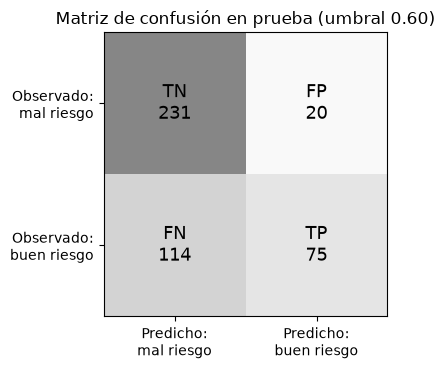

Exactitud (aciertos totales) : 70%   (decir 'mal riesgo' a todos acertaría 57%)
Sensibilidad                 : 40%   de los clientes buenos dejamos pasar
Especificidad                : 92%   de los clientes malos frenamos
Precisión                    : 79%   de los que dejamos pasar son realmente buenos


In [6]:
UMBRAL = 0.60        # ilustrativo: es una decisión de negocio, no algo que digan los datos

pasa = p_pru >= UMBRAL
tn, fp, fn, tp = confusion_matrix(y_pru, pasa).ravel()
matriz = np.array([[tn, fp], [fn, tp]])

fig, ax = plt.subplots(figsize=(4.8, 3.8))
ax.imshow(matriz, cmap="Greys", vmin=0, vmax=matriz.max() * 1.8)
etiquetas = [["TN", "FP"], ["FN", "TP"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{etiquetas[i][j]}\n{matriz[i, j]}", ha="center", va="center", fontsize=13, color="black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Predicho:\nmal riesgo", "Predicho:\nbuen riesgo"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Observado:\nmal riesgo", "Observado:\nbuen riesgo"])
ax.set_title(f"Matriz de confusión en prueba (umbral {UMBRAL:.2f})")
plt.tight_layout(); plt.show()

exactitud     = (tp + tn) / len(y_pru)
sensibilidad  = tp / (tp + fn)        # de los clientes buenos, ¿cuántos dejamos pasar?
especificidad = tn / (tn + fp)        # de los clientes malos, ¿cuántos frenamos?
precision     = tp / (tp + fp)        # de los que dejamos pasar, ¿cuántos son realmente buenos?
print(f"Exactitud (aciertos totales) : {exactitud:.0%}   (decir 'mal riesgo' a todos acertaría {1 - base:.0%})")
print(f"Sensibilidad                 : {sensibilidad:.0%}   de los clientes buenos dejamos pasar")
print(f"Especificidad                : {especificidad:.0%}   de los clientes malos frenamos")
print(f"Precisión                    : {precision:.0%}   de los que dejamos pasar son realmente buenos")

Ahora la **curva ROC**: muestra qué pasa con la sensibilidad y con los falsos positivos al mover el umbral de 0 a 1. Cuanto más cerca de la esquina superior izquierda, mejor; la diagonal es el azar.

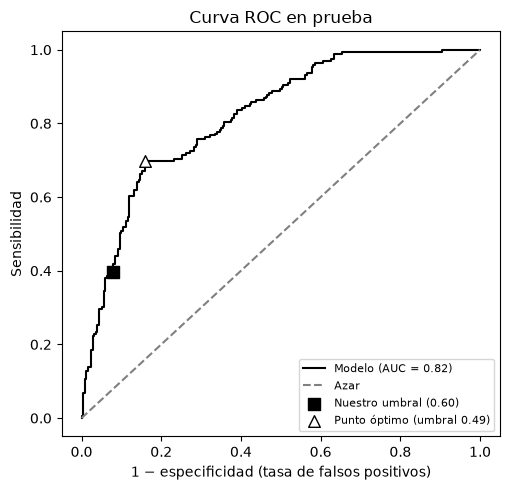

Nuestro umbral 0.60: sensibilidad 40%, 1 − especificidad 8%
Punto óptimo (umbral 0.49): sensibilidad 70%, 1 − especificidad 16%


In [7]:
fpr, tpr, cortes = roc_curve(y_pru, p_pru)
i_opt = np.argmax(tpr - fpr)                               # punto óptimo: máxima sensibilidad + especificidad - 1
fp_tasa = fp / (fp + tn)                                   # 1 - especificidad en nuestro umbral

fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot(fpr, tpr, color="black", label=f"Modelo (AUC = {roc_auc_score(y_pru, p_pru):.2f})")
ax.plot([0, 1], [0, 1], color="grey", ls="--", label="Azar")
ax.scatter([fp_tasa], [sensibilidad], marker="s", s=70, color="black", zorder=3, label=f"Nuestro umbral ({UMBRAL:.2f})")
ax.scatter([fpr[i_opt]], [tpr[i_opt]], marker="^", s=70, facecolor="white", edgecolor="black", zorder=3,
           label=f"Punto óptimo (umbral {cortes[i_opt]:.2f})")
ax.set_xlabel("1 − especificidad (tasa de falsos positivos)"); ax.set_ylabel("Sensibilidad")
ax.set_title("Curva ROC en prueba"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

print(f"Nuestro umbral {UMBRAL:.2f}: sensibilidad {sensibilidad:.0%}, 1 − especificidad {fp_tasa:.0%}")
print(f"Punto óptimo (umbral {cortes[i_opt]:.2f}): sensibilidad {tpr[i_opt]:.0%}, 1 − especificidad {fpr[i_opt]:.0%}")

El **punto óptimo** es el que maximiza sensibilidad + especificidad − 1, es decir, trata los dos errores como igual de graves. Nosotros **no** elegimos ese punto: usamos un umbral más estricto, porque dejar pasar a un cliente malo (FP) cuesta más al banco que mandar a revisión a un cliente bueno (FN).

## 5. El umbral

Un umbral más estricto deja pasar a menos clientes. La pregunta es si deja pasar *proporcionalmente* a menos clientes malos.

Sin ningún modelo, el 57% de los clientes es mal riesgo.

 umbral clientes que pasan mal riesgo entre ellos
    0.5                38%                    23%
    0.6                22%                    21%
    0.7                 7%                    14%
    0.8                 0%                      -


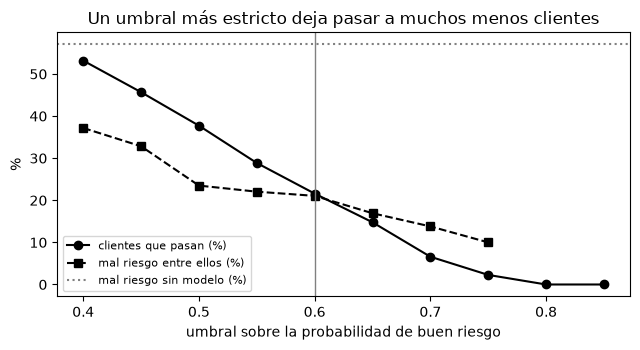

In [8]:
y = y_pru.to_numpy()
filas = []
for corte in [0.5, 0.6, 0.7, 0.8]:
    pasan = p_pru >= corte
    malos = f"{(y[pasan] == 0).mean():.0%}" if pasan.any() else "-"
    filas.append({"umbral": corte, "clientes que pasan": f"{pasan.mean():.0%}", "mal riesgo entre ellos": malos})
print(f"Sin ningún modelo, el {1 - base:.0%} de los clientes es mal riesgo.\n")
print(pd.DataFrame(filas).to_string(index=False))

cortes_g = np.arange(0.40, 0.86, 0.05)
pasan_pct = [(p_pru >= c).mean() * 100 for c in cortes_g]
malos_pct = [(y[p_pru >= c] == 0).mean() * 100 if (p_pru >= c).any() else np.nan for c in cortes_g]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(cortes_g, pasan_pct, marker="o", color="black", label="clientes que pasan (%)")
ax.plot(cortes_g, malos_pct, marker="s", color="black", ls="--", label="mal riesgo entre ellos (%)")
ax.axhline((1 - base) * 100, color="grey", ls=":", label="mal riesgo sin modelo (%)")
ax.axvline(UMBRAL, color="grey", lw=1)
ax.set_xlabel("umbral sobre la probabilidad de buen riesgo"); ax.set_ylabel("%"); ax.legend(fontsize=8)
ax.set_title("Un umbral más estricto deja pasar a muchos menos clientes")
plt.tight_layout(); plt.show()

**Qué nos dice esto.** Subir el umbral reduce la proporción de clientes malos entre los que pasan, pero a cambio deja pasar a muchos menos clientes. Por tanto, el umbral es una **decisión de negocio sobre cuántos clientes avanzan**, no un hallazgo de los datos. Usamos 0,60 como ilustración. El valor real lo fija el banco, porque depende de cuánto cuesta un "adelante" equivocado frente a rechazar por error a un buen cliente.

Por eso el mensaje es siempre **orientativo**: el modelo es un primer filtro.

**Examen final con el reservado.** Con el umbral ya elegido, confirmamos el resultado con el grupo reservado.

In [9]:
p_res = modelo.predict_proba(X_res)[:, 1]
pasa_res = p_res >= UMBRAL
tn_r, fp_r, fn_r, tp_r = confusion_matrix(y_res, pasa_res).ravel()
print(f"Reservado ({len(y_res)} clientes), umbral {UMBRAL:.2f}")
print(f"   AUC: {roc_auc_score(y_res, p_res):.2f}")
print(f"   Pasan: {pasa_res.mean():.0%}   |   mal riesgo entre los que pasan: {fp_r / (fp_r + tp_r):.0%}")
print(f"   TN {tn_r}   FP {fp_r}   FN {fn_r}   TP {tp_r}")

Reservado (99 clientes), umbral 0.60
   AUC: 0.80
   Pasan: 17%   |   mal riesgo entre los que pasan: 24%
   TN 52   FP 4   FN 30   TP 13


Con solo unos 100 clientes, este resultado es orientativo y puede variar bastante según qué clientes toquen. Lo importante es que no es muy distinto al de prueba, así que el modelo no parece haberse ajustado de más a los clientes de prueba.

## 6. El modelo final

Ahora entrenamos el modelo final con **todos** los clientes y lo envolvemos en una función pequeña que hace lo que haría el chatbot: comprobar que los valores están dentro de lo que cubren los datos, estimar la probabilidad, compararla con el umbral y elegir el mensaje.

In [10]:
VARIABLES = NUMERICAS + CATEGORICAS
modelo_final = construir_modelo(NUMERICAS, CATEGORICAS).fit(df[VARIABLES], df["risk"])
cubierto = df[NUMERICAS].agg(["min", "max"])              # los rangos que el modelo ha visto
NOMBRES = {"age": "edad", "income": "ingresos", "numcards": "número de tarjetas", "storecar": "storecar",
           "loans": "número de préstamos", "numkids": "número de hijos",
           "mortgage": "hipoteca", "howpaid": "forma de pago", "marital": "estado civil"}
VALIDAS = {col: set(df[col].dropna().unique()) for col in CATEGORICAS}

def precheck(cliente):
    fila = pd.DataFrame([cliente])[VARIABLES]
    for col in NUMERICAS:                                  # nunca extrapolamos más allá de los datos
        if not cubierto.loc["min", col] <= fila[col].iloc[0] <= cubierto.loc["max", col]:
            return None, (f"No podemos dar una estimación: {NOMBRES[col]} = {fila[col].iloc[0]:g} está fuera del rango "
                          f"que cubren nuestros datos ({cubierto.loc['min', col]:g} a {cubierto.loc['max', col]:g}).")
    for col in CATEGORICAS:                                # ni valores que el modelo no conoce
        if fila[col].iloc[0] not in VALIDAS[col]:
            return None, (f"No podemos dar una estimación: el valor '{fila[col].iloc[0]}' de {NOMBRES[col]} "
                          f"no es uno de los que aparecen en nuestros datos.")
    prob = modelo_final.predict_proba(fila)[0, 1]
    if prob >= UMBRAL:
        msg = "Potencialmente elegible (orientativo). Continuaremos con el cálculo de tu cuota mensual."
    else:
        msg = "Con la información actual podrías no ser elegible (orientativo). Puedes pedir que se revise tu caso."
    return prob, msg

El modelo de lenguaje del chatbot solo convierte las palabras del cliente en estos campos y devuelve el resultado en una frase amable. Nunca calcula la probabilidad ni elige el mensaje.

## 7. Pruébalo tú mismo

Escribe los datos de un cliente, pulsa el botón y obtén la respuesta del chatbot. Usa la misma función `precheck()` de arriba, así que el formulario siempre coincide con el modelo final.

*Ejecuta la celda de abajo (en Jupyter, VS Code o Colab). Los deslizadores están limitados a los rangos que cubren los datos; la edad y los ingresos se pueden escribir libremente, y los valores fuera del rango muestran el mensaje de "no podemos dar una estimación".*

In [11]:
import ipywidgets as widgets
from IPython.display import display, clear_output

def describir(cliente):
    '''Ejecuta el pre-check y devuelve el texto que ve el usuario.'''
    prob, mensaje = precheck(cliente)
    lineas = ["PRE-CHECK DE ELEGIBILIDAD HIPOTECARIA", "=" * 38,
              f"Edad: {cliente['age']:g}   Ingresos: {cliente['income']:,.0f}",
              f"Tarjetas: {cliente['numcards']}   Storecar: {cliente['storecar']}   Préstamos: {cliente['loans']}   Hijos: {cliente['numkids']}",
              f"Estado civil: {cliente['marital']}",
              f"Hipoteca existente: {cliente['mortgage']}   Forma de pago (w/m): {cliente['howpaid']}",
              "-" * 38]
    if prob is None:
        lineas.append("PROBABILIDAD ESTIMADA DE BUEN RIESGO: no disponible")
    else:
        lineas.append(f"PROBABILIDAD ESTIMADA DE BUEN RIESGO: {prob:.0%}   (umbral {UMBRAL:.0%})")
    lineas += [mensaje, "", "Nota: resultado solo orientativo. Un especialista confirma cada caso."]
    return "\n".join(lineas)

# Campos de entrada
edad_input     = widgets.FloatText(value=35, description="Edad:", style={"description_width": "initial"}, layout=widgets.Layout(width="350px"))
ingresos_input = widgets.FloatText(value=40000, description="Ingresos:", style={"description_width": "initial"}, layout=widgets.Layout(width="350px"))
tarjetas_input = widgets.IntSlider(value=1, min=int(cubierto.loc["min", "numcards"]), max=int(cubierto.loc["max", "numcards"]), description="Nº de tarjetas:", style={"description_width": "initial"}, continuous_update=False, layout=widgets.Layout(width="400px"))
storecar_input = widgets.IntSlider(value=1, min=int(cubierto.loc["min", "storecar"]), max=int(cubierto.loc["max", "storecar"]), description="Storecar (tarjetas de tienda):", style={"description_width": "initial"}, continuous_update=False, layout=widgets.Layout(width="400px"))
prestamos_input = widgets.IntSlider(value=0, min=int(cubierto.loc["min", "loans"]), max=int(cubierto.loc["max", "loans"]), description="Nº de préstamos:", style={"description_width": "initial"}, continuous_update=False, layout=widgets.Layout(width="400px"))
hijos_input    = widgets.IntSlider(value=1, min=int(cubierto.loc["min", "numkids"]), max=int(cubierto.loc["max", "numkids"]), description="Nº de hijos:", style={"description_width": "initial"}, continuous_update=False, layout=widgets.Layout(width="400px"))
civil_input    = widgets.Dropdown(options=[("Soltero/a", "s"), ("Casado/a", "m"), ("Divorciado/a, separado/a o viudo/a", "dsw")], value="m", description="Estado civil:", style={"description_width": "initial"}, layout=widgets.Layout(width="450px"))
hipoteca_input = widgets.Dropdown(options=[("No", "n"), ("Sí", "y")], value="n", description="Hipoteca existente:", style={"description_width": "initial"}, layout=widgets.Layout(width="350px"))
pago_input     = widgets.Dropdown(options=["w", "m"], value="w", description="Forma de pago (w / m):", style={"description_width": "initial"}, layout=widgets.Layout(width="350px"))

boton = widgets.Button(description="Comprobar elegibilidad", button_style="success", icon="calculator", layout=widgets.Layout(width="240px"))
salida = widgets.Output()

def al_comprobar(_):
    with salida:
        clear_output(wait=True)
        try:
            cliente = dict(age=edad_input.value, income=ingresos_input.value, numcards=tarjetas_input.value,
                           storecar=storecar_input.value, loans=prestamos_input.value,
                           numkids=hijos_input.value, marital=civil_input.value,
                           mortgage=hipoteca_input.value, howpaid=pago_input.value)
            print(describir(cliente))
        except (ValueError, TypeError) as error:
            print(f"No se puede ejecutar el pre-check: {error}")

boton.on_click(al_comprobar)

display(widgets.VBox([
    widgets.HTML("<h2>Pre-check de elegibilidad hipotecaria</h2>"),
    widgets.HTML("<p>Introduce los datos del cliente para obtener un resultado orientativo.</p>"),
    edad_input, ingresos_input, tarjetas_input, storecar_input, prestamos_input, hijos_input, civil_input, hipoteca_input, pago_input,
    boton, salida,
]))